## Karunya Paliwal
## c3_c1_14
## ML LAB 7


In [ ]:
## Naive bayes classifier

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score


In [ ]:
df=pd.read_excel("Raisin_Dataset.xlsx")

In [ ]:
df.head()

,Area,MajorAxisLength,MinorAxisLength,Eccentricity,ConvexArea,Extent,Perimeter,Class
0,87524,442.246011,253.291155,0.819738,90546,0.758651,1184.040,Kecimen
1,75166,406.690687,243.032436,0.801805,78789,0.684130,1121.786,Kecimen
2,90856,442.267048,266.328318,0.798354,93717,0.637613,1208.575,Kecimen
3,45928,286.540559,208.760042,0.684989,47336,0.699599,844.162,Kecimen
4,79408,352.190770,290.827533,0.564011,81463,0.792772,1073.251,Kecimen


In [ ]:
df.tail()

,Area,MajorAxisLength,MinorAxisLength,Eccentricity,ConvexArea,Extent,Perimeter,Class
895,83248,430.077308,247.838695,0.817263,85839,0.668793,1129.072,Besni
896,87350,440.735698,259.293149,0.808629,90899,0.636476,1214.252,Besni
897,99657,431.706981,298.837323,0.721684,106264,0.741099,1292.828,Besni
898,93523,476.344094,254.176054,0.845739,97653,0.658798,1258.548,Besni
899,85609,512.081774,215.271976,0.907345,89197,0.632020,1272.862,Besni


In [ ]:
df.shape

(900, 8)

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.describe()

,Area,MajorAxisLength,MinorAxisLength,Eccentricity,ConvexArea,Extent,Perimeter
count,900.000000,900.000000,900.000000,900.000000,900.000000,900.000000,900.000000
mean,87804.127778,430.929950,254.488133,0.781542,91186.090000,0.699508,1165.906636
std,39002.111390,116.035121,49.988902,0.090318,40769.290132,0.053468,273.764315
min,25387.000000,225.629541,143.710872,0.348730,26139.000000,0.379856,619.074000
25%,59348.000000,345.442898,219.111126,0.741766,61513.250000,0.670869,966.410750
50%,78902.000000,407.803951,247.848409,0.798846,81651.000000,0.707367,1119.509000
75%,105028.250000,494.187014,279.888575,0.842571,108375.750000,0.734991,1308.389750
max,235047.000000,997.291941,492.275279,0.962124,278217.000000,0.835455,2697.753000


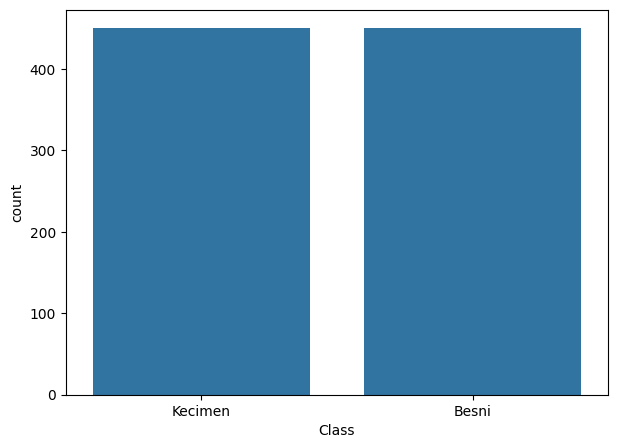

In [ ]:
plt.figure(figsize=(7,5))
sns.countplot(data=df,x="Class")
plt.show()

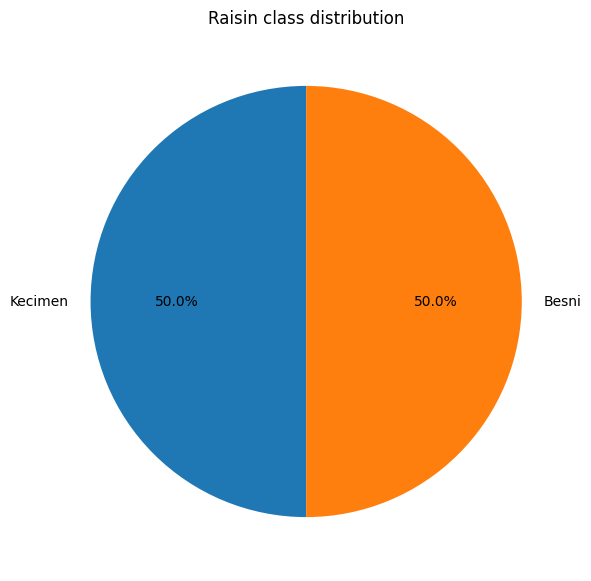

In [ ]:
class_counts=df["Class"].value_counts()
plt.figure(figsize=(7,7))
plt.pie(class_counts,labels=class_counts.index,autopct="%1.1f%%",startangle=90)


plt.title("Raisin class distribution")
plt.show()

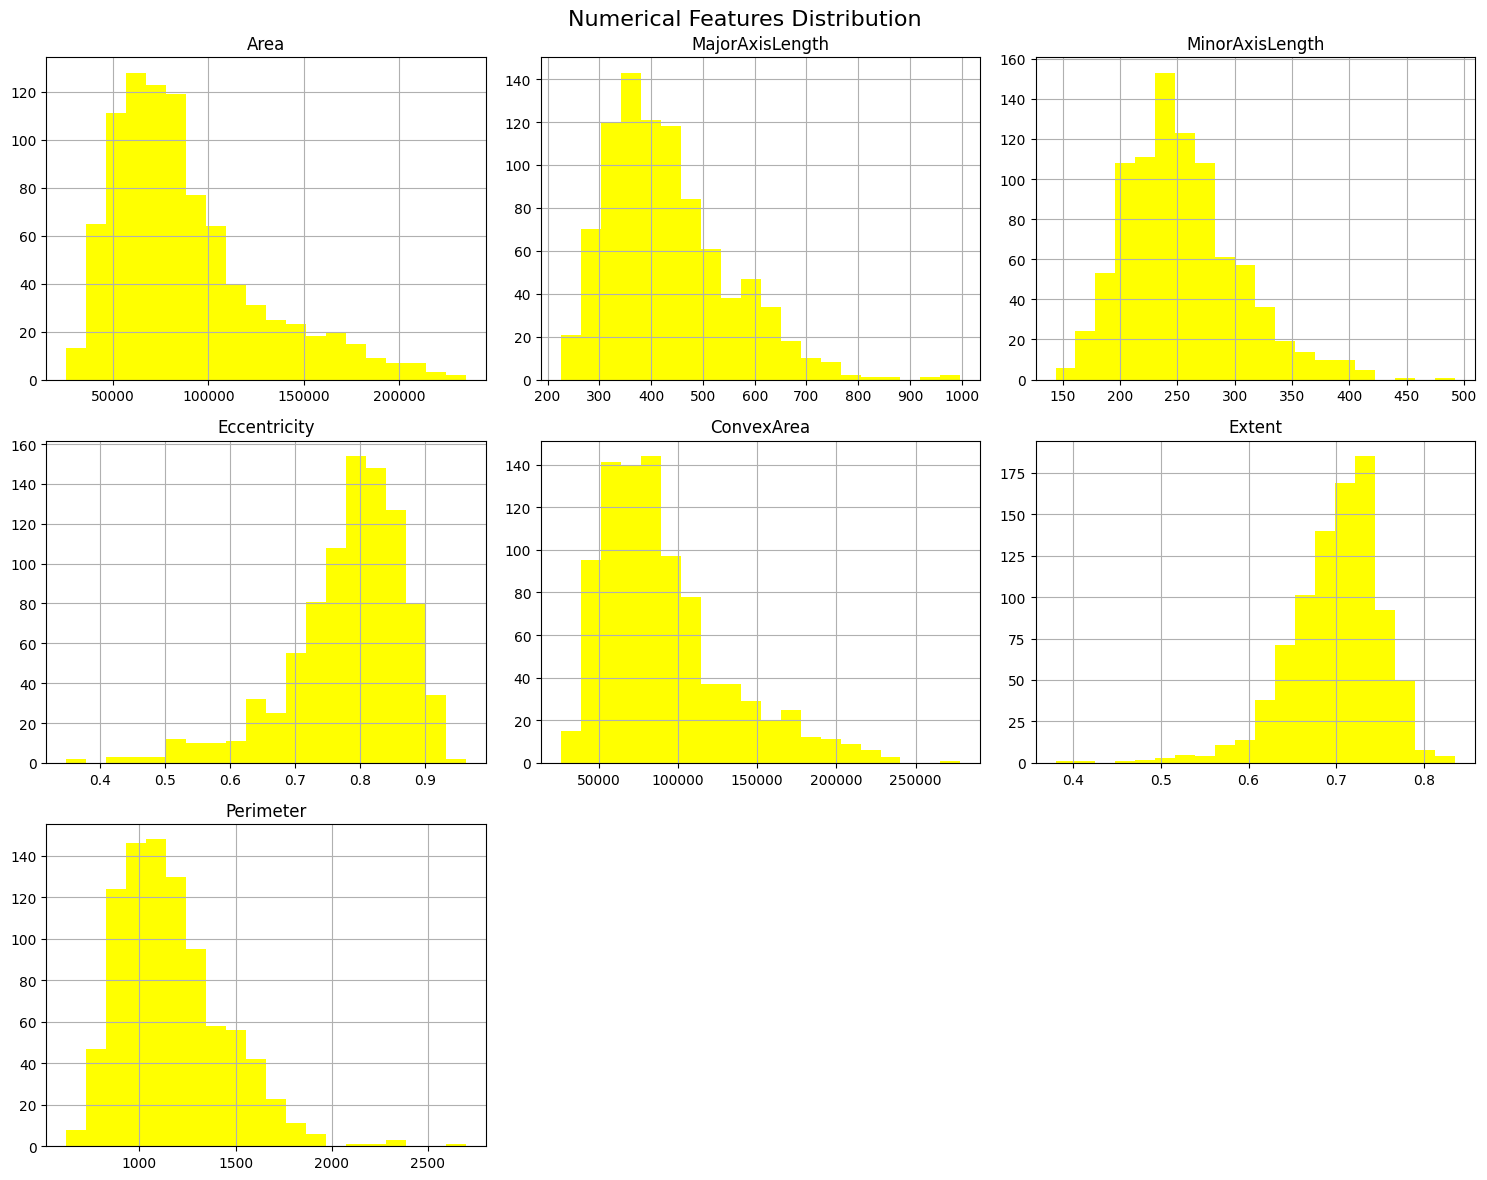

In [ ]:
numerical_features = df.select_dtypes(include=['number']).columns.tolist()
df[numerical_features].hist(figsize=(15,12),bins=20,color='yellow')
plt.suptitle("Numerical Features Distribution",fontsize=16)
plt.tight_layout()
plt.show()

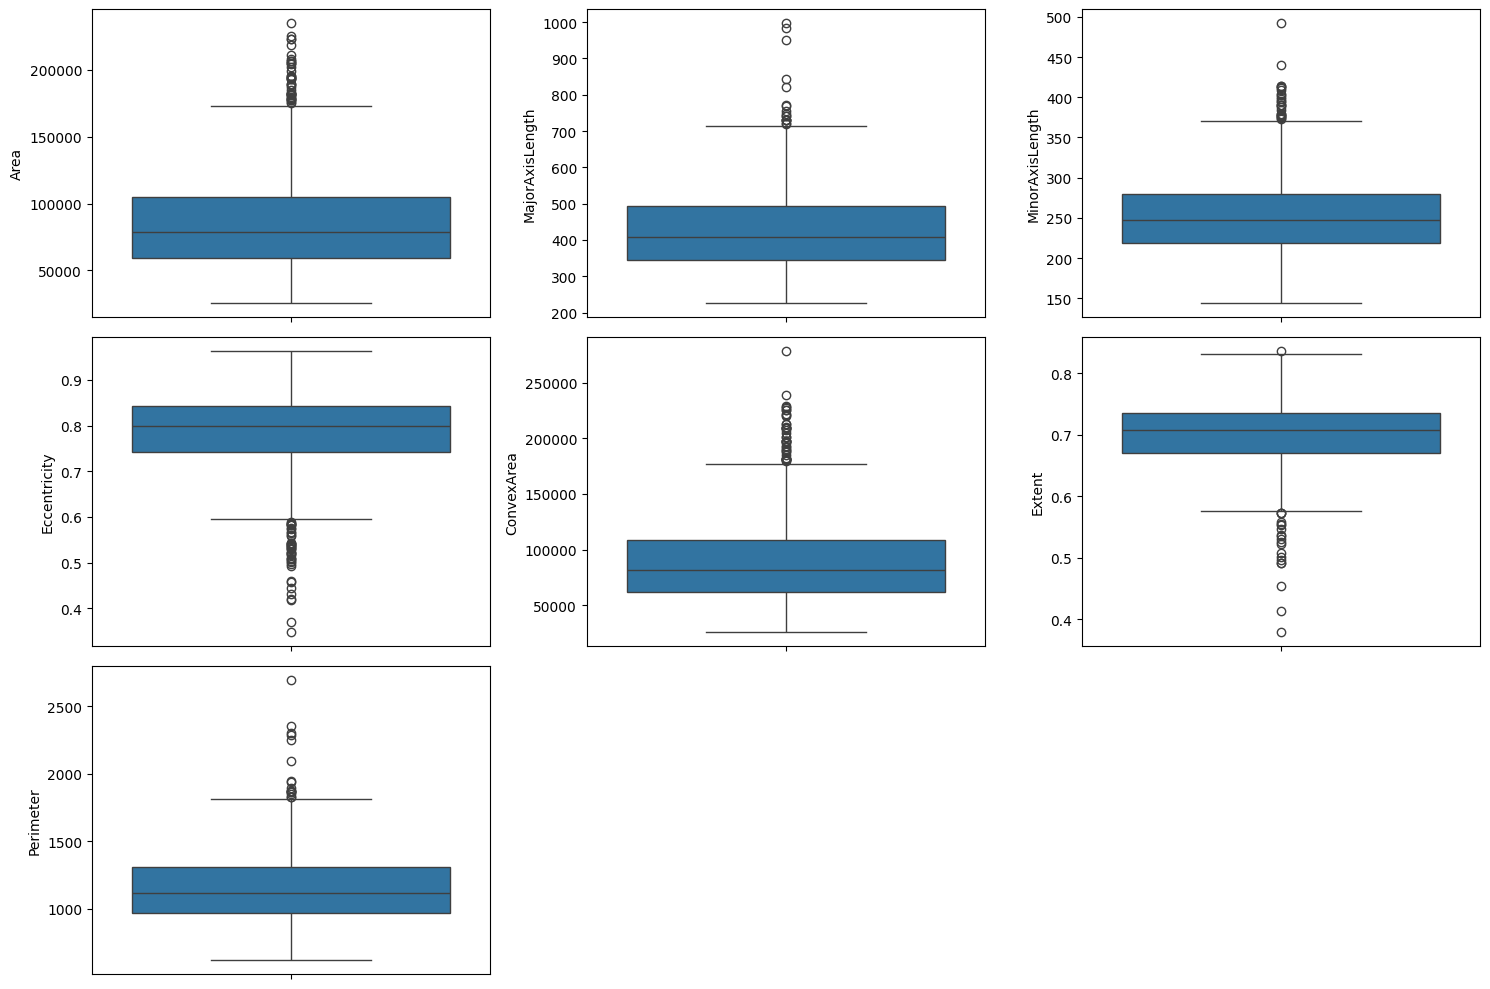

In [ ]:
plt.figure(figsize=(15,10))
for i,column in enumerate(numerical_features,1):
  plt.subplot(3, 3, i)
  sns.boxplot(y=df[column])
plt.tight_layout()
plt.show()

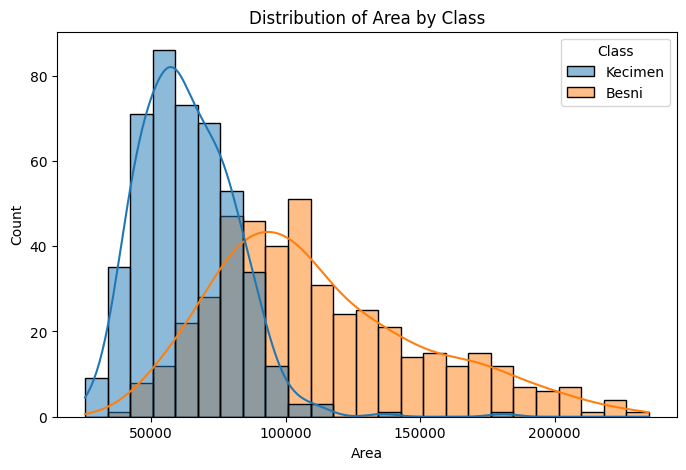

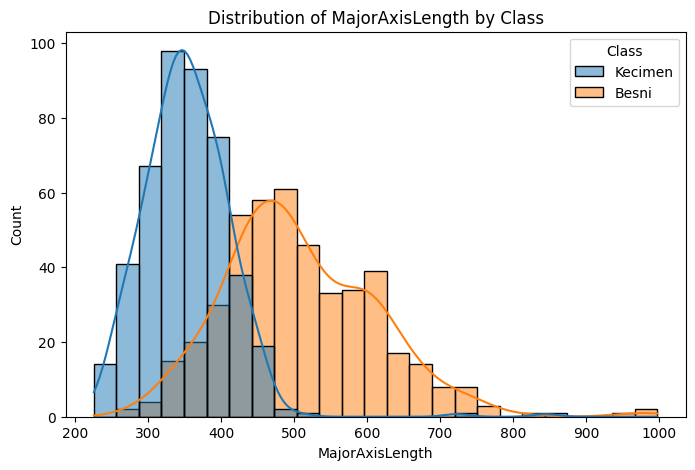

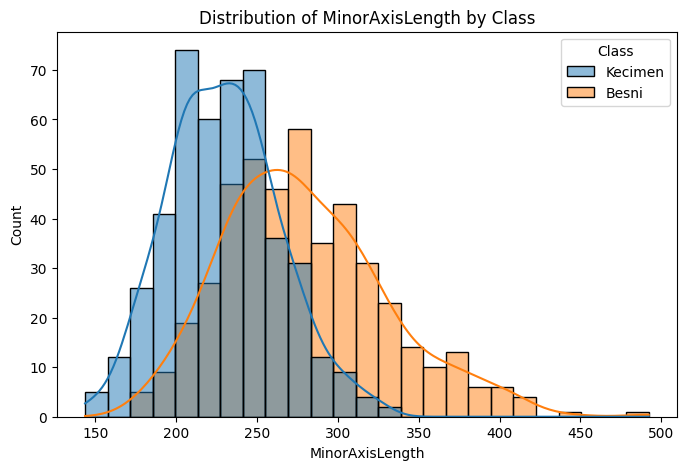

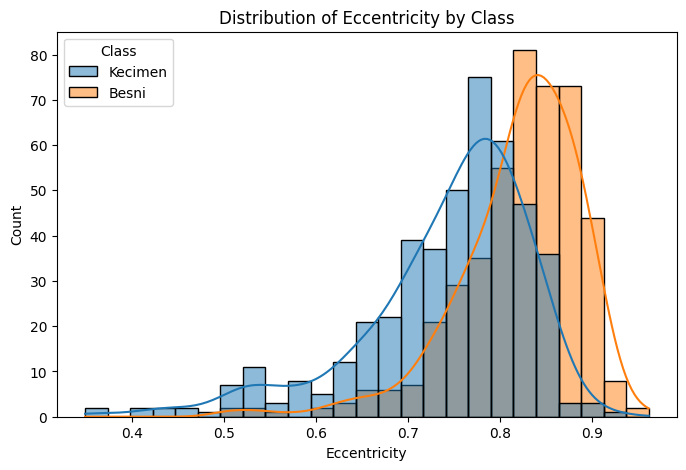

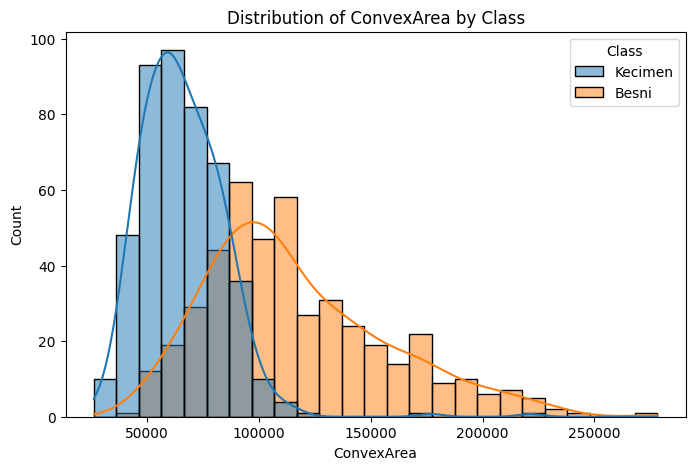

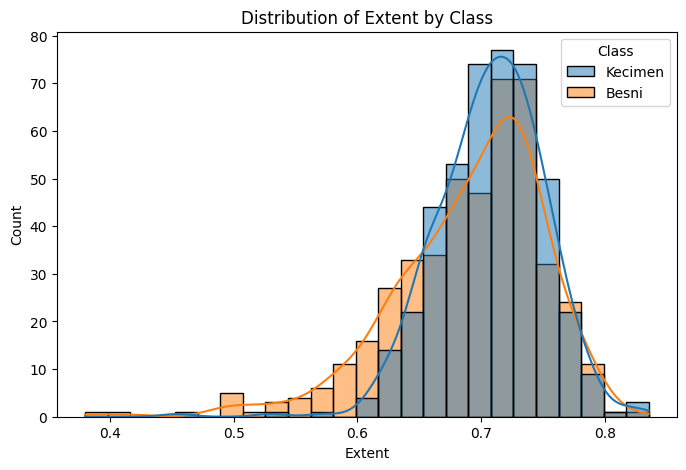

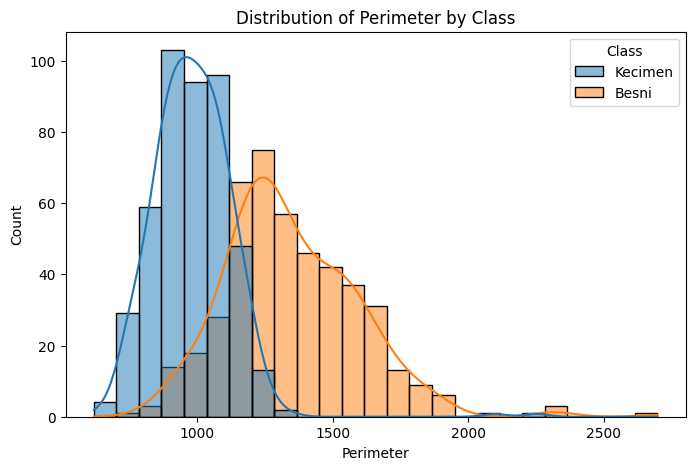

In [ ]:
for column in numerical_features:
  plt.figure(figsize=(8,5))
  sns.histplot(data=df,x=column,hue="Class",kde=True,bins=25)
  plt.title(f"Distribution of {column} by Class")
  plt.show()

<module 'matplotlib.pyplot' from '/usr/local/lib/python3.13/dist-packages/matplotlib/pyplot.py'>

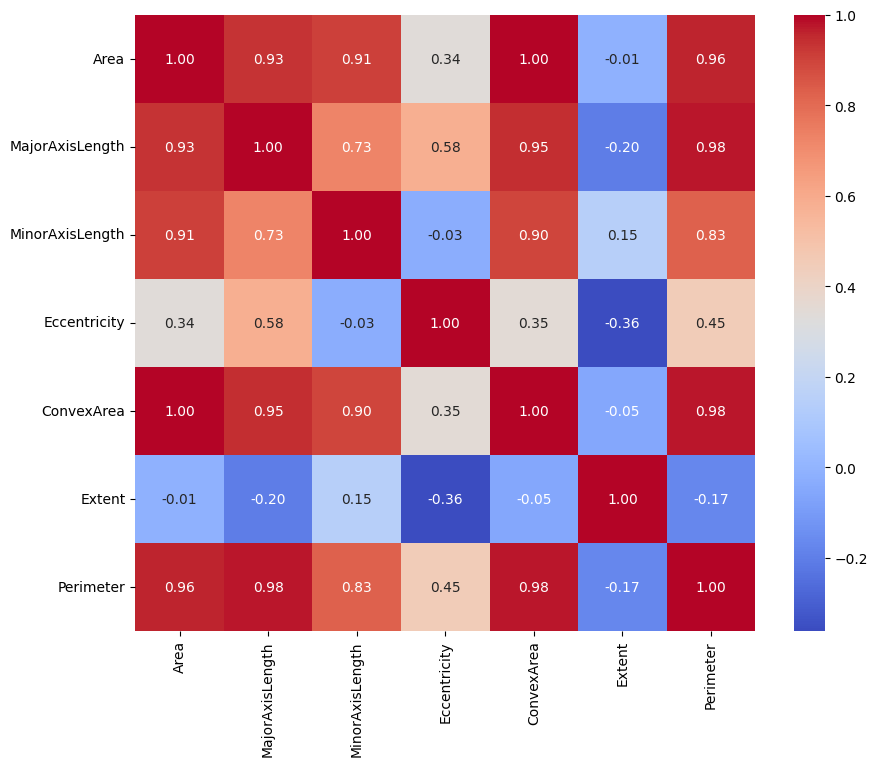

In [ ]:
correlation_matrix = df[numerical_features].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt

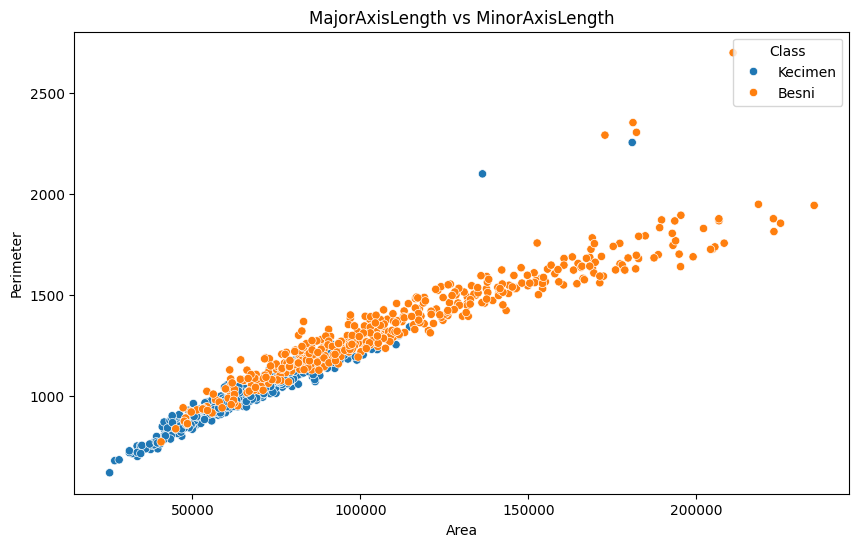

In [ ]:
plt.figure(figsize=(10,6))
sns.scatterplot(data=df,x="Area",y="Perimeter",hue="Class")
plt.title("MajorAxisLength vs MinorAxisLength")
plt.show()

In [ ]:
from sklearn.preprocessing import LabelEncoder
label_encoder=LabelEncoder()
df["class_encoded"]=label_encoder.fit_transform(df["Class"])
print(df[["Class","class_encoded"]].head())

     Class  class_encoded
0  Kecimen              1
1  Kecimen              1
2  Kecimen              1
3  Kecimen              1
4  Kecimen              1


In [ ]:
X=df[numerical_features]
y=df["class_encoded"]
print("Shape of X:",X.shape)
print("Shape of y:",y.shape)

Shape of X: (900, 7)
Shape of y: (900,)


In [ ]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)
print("Shape of X_train:",X_train.shape)
print("Shape of X_test:",X_test.shape)
print("Shape of y_train:",y_train.shape)
print("Shape of y_test:",y_test.shape)

Shape of X_train: (720, 7)
Shape of X_test: (180, 7)
Shape of y_train: (720,)
Shape of y_test: (180,)


In [ ]:
GaussianNB()

GaussianNB()

In [ ]:
gnb=GaussianNB()
gnb.fit(X_train,y_train)

GaussianNB()

In [ ]:
y_pred=gnb.predict(X_test)
print(y_pred)

[0 1 1 0 1 1 1 1 1 1 0 0 0 1 0 0 0 1 1 0 1 0 1 1 0 1 1 0 0 0 1 0 0 0 0 0 1
 0 1 1 1 1 1 1 0 0 1 1 1 1 0 1 0 1 1 1 1 1 1 0 1 1 1 1 1 1 0 0 1 1 0 0 1 1
 0 0 1 1 1 0 0 1 0 1 0 0 1 1 1 0 1 1 0 0 0 1 1 1 0 0 0 1 0 1 1 1 0 1 1 1 0
 0 1 1 0 1 1 1 1 0 1 1 1 1 0 1 1 0 1 1 0 0 0 1 1 1 0 0 0 1 1 1 0 1 0 1 0 1
 1 1 1 0 1 1 1 1 1 1 1 1 1 0 1 1 0 0 1 0 0 0 1 1 1 1 0 0 0 0 1 1]


In [ ]:
comparision=pd.DataFrame({"Actual":y_test,"Predicted":y_pred})
comparision.head(10)

,Actual,Predicted
70,1,0
827,0,1
231,1,1
588,0,0
39,1,1
731,0,1
299,1,1
110,1,1
72,1,1
86,1,1


In [ ]:
comparision["Actual_Class"]=label_encoder.inverse_transform(comparision["Actual"])
comparision["Predicted_Class"]=label_encoder.inverse_transform(comparision["Predicted"])
comparision.head(20)

,Actual,Predicted,Actual_Class,Predicted_Class
70,1,0,Kecimen,Besni
827,0,1,Besni,Kecimen
231,1,1,Kecimen,Kecimen
588,0,0,Besni,Besni
39,1,1,Kecimen,Kecimen
731,0,1,Besni,Kecimen
299,1,1,Kecimen,Kecimen
110,1,1,Kecimen,Kecimen
72,1,1,Kecimen,Kecimen
86,1,1,Kecimen,Kecimen


In [ ]:
accuracy=accuracy_score(y_test,y_pred)
print("Accuracy:",accuracy)

Accuracy: 0.8277777777777777


In [ ]:
precision=precision_score(y_test,y_pred,average="weighted")
print("Precision:",precision)

Precision: 0.8359722042756027


In [ ]:
recall=recall_score(y_test,y_pred,average="weighted")
print("Recall:",recall)

Recall: 0.8277777777777777


In [ ]:
f1=f1_score(y_test,y_pred,average="weighted")
print("F1 Score:",f1)

F1 Score: 0.8259134915405506


In [ ]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.89      0.73      0.80        86
           1       0.79      0.91      0.85        94

    accuracy                           0.83       180
   macro avg       0.84      0.82      0.82       180
weighted avg       0.84      0.83      0.83       180



In [ ]:
cm=confusion_matrix(y_test,y_pred)
print(cm)

[[63 23]
 [ 8 86]]


In [ ]:
from sklearn.metrics import accuracy_score
y_train_pred=gnb.predict(X_train)
y_test_pred=gnb.predict(X_test)
test_accuracy=accuracy_score(y_test,y_test_pred)
print("Testing Accuracy:",test_accuracy)
train_accuracy=accuracy_score(y_train,y_train_pred)
print("Training Accuracy:",train_accuracy)

Testing Accuracy: 0.8277777777777777
Training Accuracy: 0.8222222222222222
